## Wisconsin Breast Cancer Dataset - OCSMM SHAP

In [1]:
from ucimlrepo import fetch_ucirepo 
import pandas as pd
# fetch dataset 
breast_cancer_wisconsin_original = fetch_ucirepo(id=15) 
  
# data (as pandas dataframes) 
X = breast_cancer_wisconsin_original.data.features 
y = breast_cancer_wisconsin_original.data.targets 

X = X.drop(columns=['Bare_nuclei']) # this feature has missing values
feature_names = X.columns.tolist()

X = pd.DataFrame(X, columns=X.columns)

# metadata 
print(breast_cancer_wisconsin_original.metadata) 
  
# variable information 
print(breast_cancer_wisconsin_original.variables) 


{'uci_id': 15, 'name': 'Breast Cancer Wisconsin (Original)', 'repository_url': 'https://archive.ics.uci.edu/dataset/15/breast+cancer+wisconsin+original', 'data_url': 'https://archive.ics.uci.edu/static/public/15/data.csv', 'abstract': 'Original Wisconsin Breast Cancer Database', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 699, 'num_features': 9, 'feature_types': ['Integer'], 'demographics': [], 'target_col': ['Class'], 'index_col': ['Sample_code_number'], 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1990, 'last_updated': 'Sun Mar 10 2024', 'dataset_doi': '10.24432/C5HP4Z', 'creators': ['WIlliam Wolberg'], 'intro_paper': None, 'additional_info': {'summary': "Samples arrive periodically as Dr. Wolberg reports his clinical cases. The database therefore reflects this chronological grouping of the data. This grouping information appears immediately below, having been removed fro

In [2]:
X.shape

(699, 8)

In [3]:
unique_counts = {col: X[col].value_counts() for col in X.columns}

# Print the number of unique values and their counts for each feature
for feature, counts in unique_counts.items():
    print(f"Feature: {feature}")
    print(f"Number of unique values: {counts.shape[0]}")
    print(counts, "\n")

Feature: Clump_thickness
Number of unique values: 10
Clump_thickness
1     145
5     130
3     108
4      80
10     69
2      50
8      46
6      34
7      23
9      14
Name: count, dtype: int64 

Feature: Uniformity_of_cell_size
Number of unique values: 10
Uniformity_of_cell_size
1     384
10     67
3      52
2      45
4      40
5      30
8      29
6      27
7      19
9       6
Name: count, dtype: int64 

Feature: Uniformity_of_cell_shape
Number of unique values: 10
Uniformity_of_cell_shape
1     353
2      59
10     58
3      56
4      44
5      34
7      30
6      30
8      28
9       7
Name: count, dtype: int64 

Feature: Marginal_adhesion
Number of unique values: 10
Marginal_adhesion
1     407
3      58
2      58
10     55
4      33
8      25
5      23
6      22
7      13
9       5
Name: count, dtype: int64 

Feature: Single_epithelial_cell_size
Number of unique values: 10
Single_epithelial_cell_size
2     386
3      72
4      48
1      47
6      41
5      39
10     31
8      21
7

In [4]:
import numpy as np

In [5]:
grouped_data = []

# Group by 'Bland_chromatin' and process each group
for _, group in X.groupby('Bland_chromatin'):
    # Drop the Bland_chromatin' column and convert the group to a NumPy array
    group_data = group.drop(columns=['Bland_chromatin']).to_numpy()

    # Append the group as a NumPy array into the grouped_data list
    grouped_data.append(group_data)

In [6]:
grouped_data

[array([[2, 1, 1, ..., 2, 1, 5],
        [1, 1, 3, ..., 2, 1, 1],
        [3, 1, 1, ..., 2, 1, 1],
        ...,
        [3, 1, 1, ..., 2, 1, 1],
        [3, 1, 1, ..., 3, 1, 1],
        [2, 1, 1, ..., 2, 1, 1]], shape=(152, 7)),
 array([[4, 2, 1, ..., 2, 1, 1],
        [2, 1, 1, ..., 2, 1, 1],
        [4, 1, 1, ..., 2, 1, 1],
        ...,
        [1, 1, 2, ..., 2, 1, 1],
        [3, 1, 1, ..., 2, 3, 1],
        [3, 1, 1, ..., 2, 1, 2]], shape=(166, 7)),
 array([[5, 1, 1, ..., 2, 1, 1],
        [5, 4, 4, ..., 7, 2, 1],
        [3, 1, 1, ..., 2, 1, 1],
        ...,
        [3, 2, 1, ..., 2, 1, 1],
        [2, 1, 1, ..., 2, 1, 1],
        [5, 1, 1, ..., 2, 2, 1]], shape=(165, 7)),
 array([[ 5,  3,  3,  3,  2,  4,  1],
        [ 7,  4,  6,  4,  6,  3,  1],
        [10,  7,  7,  6,  4,  1,  2],
        [ 3,  7,  7,  4,  4,  8,  1],
        [10,  3,  6,  2,  3, 10,  2],
        [ 5,  3,  5,  5,  3, 10,  1],
        [10,  4,  2,  1,  3,  3, 10],
        [ 5,  3,  4,  1,  8,  9,  1],
        [

In [7]:
datasets = grouped_data

In [8]:
from src.ocsmm.OneClassSMMClassifier import OneClassSMMClassifier

In [9]:
classifier = OneClassSMMClassifier(nu=0.2)

In [10]:
classifier.fit(datasets)

Best gamma found.

Kappa matrix calculated.

Found the alphas.



In [11]:
decision, y_pred = classifier.predict(datasets)

Calculating kappa.

calculating rho.

0.5519600102233567


In [12]:
decision

array([ 4.10287038e-07,  4.33294151e-03,  5.53775486e-02,  8.50494250e-02,
        8.04188455e-02,  1.65563563e-02,  8.75072857e-02,  1.86581949e-03,
       -2.31937355e-07, -1.78349683e-07])

In [13]:
y_pred

array([ 1.,  1.,  1.,  1.,  1.,  1.,  1.,  1., -1., -1.])

In [14]:
outlier_indices = [i for i, value in enumerate(y_pred) if value == -1]
outlier_indices

[8, 9]

In [15]:
feature_names.remove("Bland_chromatin")

In [16]:
from src.explanation_algorithms.OCSMMSHAP import OCSMMSHAP
ocsmm_shap = OCSMMSHAP(X=datasets, classifier=classifier, decision=decision)
ocsmm_shap.fit_ocsmmshap(X=datasets, num_coalitions=2**len(feature_names))

Calculating projections: 100%|██████████| 127/127 [00:00<00:00, 304.26it/s]


In [17]:
shapley_values = ocsmm_shap.return_deterministic_shapley_values()

In [18]:
shapley_values = shapley_values.T*100

In [19]:
feature_names

['Clump_thickness',
 'Uniformity_of_cell_size',
 'Uniformity_of_cell_shape',
 'Marginal_adhesion',
 'Single_epithelial_cell_size',
 'Normal_nucleoli',
 'Mitoses']

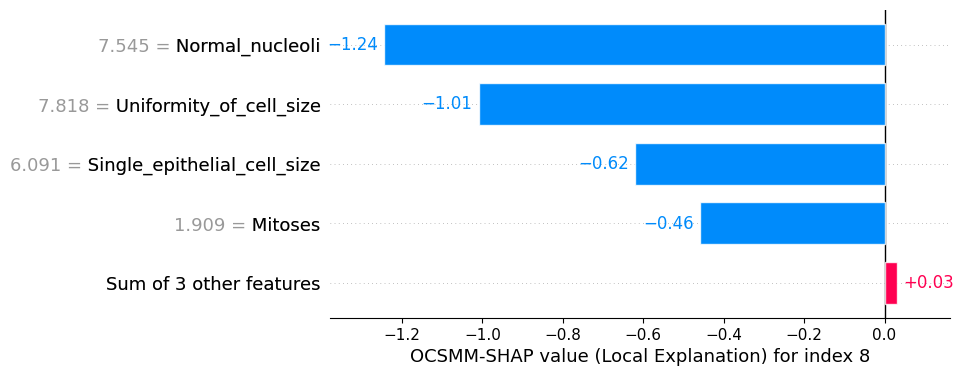

In [20]:
from src.utils.visualisation.deterministic_values import local_bar_plot_ocsmm, global_bar_plot_ocsmm
local_bar_plot_ocsmm(shapley_values.numpy(), 8, feature_names=feature_names, datasets=datasets)

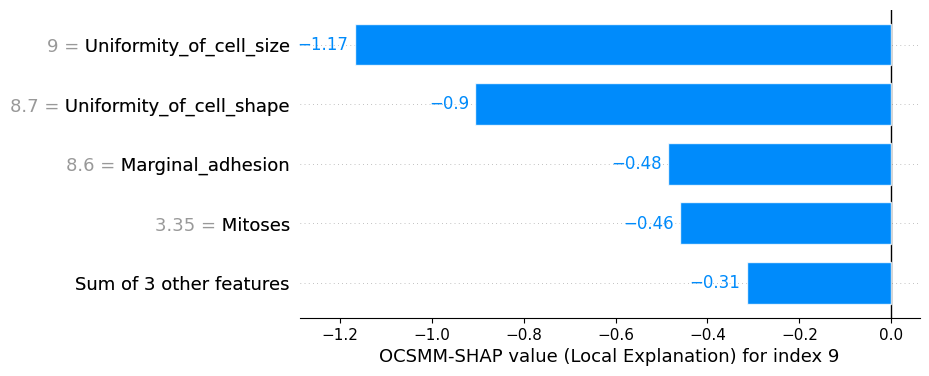

In [22]:
local_bar_plot_ocsmm(shapley_values.numpy(), 9, feature_names=feature_names, datasets=datasets)

/tmp/ipykernel_3407115/3176113499.py:2: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  mean_abs_shap_values = np.abs(shapley_values).mean(axis=0)


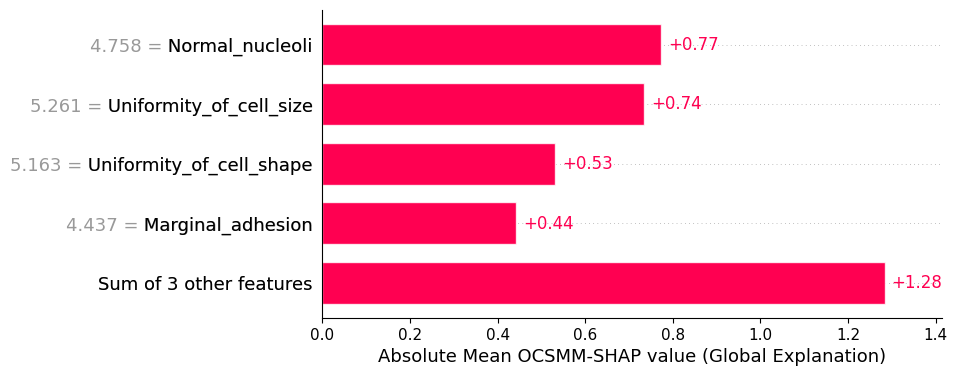

In [23]:
# global importance measure
mean_abs_shap_values = np.abs(shapley_values).mean(axis=0)  

# Call bar_plot for global explanation
global_bar_plot_ocsmm(mean_abs_shap_values.numpy(), feature_names=feature_names, datasets=datasets)

In [31]:
from src.explanation_algorithms.OCSMMSHAPIQ_Approx import OCSMMSHAPIQ, display_network_plot
shapiq = OCSMMSHAPIQ(n=len(feature_names), max_order=2, random_state=2)
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[8],
    X=datasets,  
    model=classifier,
    regularization=1e-4,
    budget=2**len(feature_names))

100%|██████████| 128/128 [00:00<00:00, 52439.04it/s]


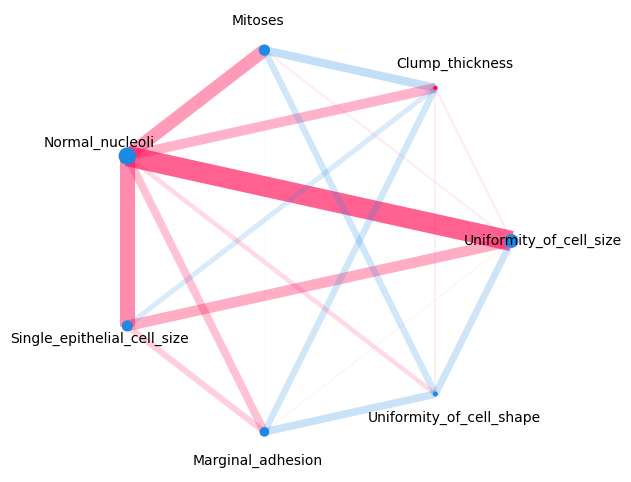

In [32]:
display_network_plot(interactions_per_group, feature_names=feature_names)

In [33]:
shapiq = OCSMMSHAPIQ(n=len(feature_names), max_order=2, random_state=2)
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[9],
    X=datasets,  
    model=classifier,
    regularization=1e-4,
    budget=2**len(feature_names))


100%|██████████| 128/128 [00:00<00:00, 52836.42it/s]


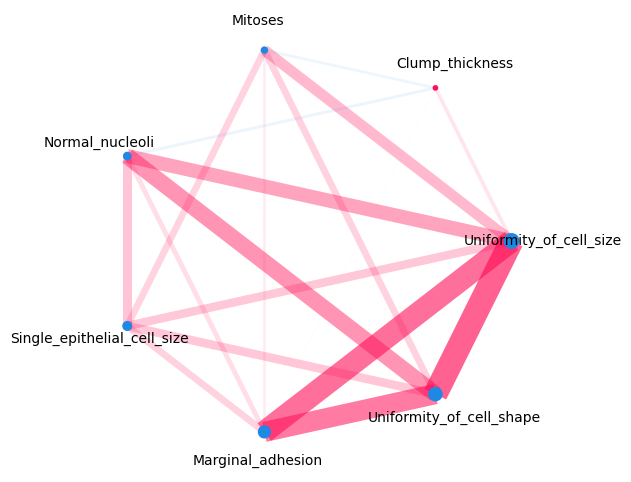

In [34]:
display_network_plot(interactions_per_group, feature_names=feature_names)

## Add an artificial feature

In [35]:
X_scaled_df = pd.DataFrame(X, columns=X.columns)
grouped_data = []

for i, (_, group) in enumerate(X_scaled_df.groupby('Normal_nucleoli')):
    group_data = group.drop(columns=['Normal_nucleoli']).to_numpy()
    artificial_feature = np.ones((group_data.shape[0],1))  # Default value = 1
    if i == 0 : 
        artificial_feature.fill(3)
    
    group_data = np.hstack((group_data, artificial_feature))  # Append feature
    grouped_data.append(group_data)

In [36]:
feature_names.append('artificial_feature')

In [37]:
datasets = grouped_data

In [38]:
datasets

[array([[5., 1., 1., ..., 3., 1., 3.],
        [3., 1., 1., ..., 3., 1., 3.],
        [4., 1., 1., ..., 3., 1., 3.],
        ...,
        [3., 1., 1., ..., 2., 2., 3.],
        [3., 1., 1., ..., 1., 1., 3.],
        [2., 1., 1., ..., 1., 1., 3.]], shape=(443, 8)),
 array([[ 5.,  4.,  4.,  5.,  7.,  3.,  1.,  1.],
        [ 1.,  1.,  1.,  1.,  2.,  3.,  1.,  1.],
        [ 1.,  3.,  3.,  2.,  2.,  7.,  1.,  1.],
        [10.,  6.,  4.,  1.,  3.,  3.,  3.,  1.],
        [ 1.,  1.,  2.,  1.,  2.,  4.,  1.,  1.],
        [ 7.,  3.,  4.,  4.,  3.,  3.,  7.,  1.],
        [ 8.,  3.,  3.,  1.,  2.,  3.,  1.,  1.],
        [ 3.,  1.,  1.,  1.,  2.,  2.,  1.,  1.],
        [ 4.,  1.,  1.,  1.,  2.,  3.,  1.,  1.],
        [ 4.,  1.,  1.,  1.,  2.,  3.,  1.,  1.],
        [ 5.,  1.,  4.,  1.,  2.,  3.,  1.,  1.],
        [ 3.,  1.,  1.,  1.,  2.,  3.,  1.,  1.],
        [ 5.,  2.,  2.,  2.,  2.,  2.,  1.,  1.],
        [ 4.,  1.,  1.,  1.,  3.,  2.,  1.,  1.],
        [ 3.,  1.,  1.,  4.,  3.,  

In [39]:
feature_names

['Clump_thickness',
 'Uniformity_of_cell_size',
 'Uniformity_of_cell_shape',
 'Marginal_adhesion',
 'Single_epithelial_cell_size',
 'Normal_nucleoli',
 'Mitoses',
 'artificial_feature']

In [40]:
classifier = OneClassSMMClassifier(nu=0.2)

In [41]:
classifier.fit(datasets)

Best gamma found.

Kappa matrix calculated.

Found the alphas.



In [42]:
decision, y_pred = classifier.predict(datasets)

Calculating kappa.

calculating rho.

0.6081314145994421


In [43]:
decision

array([-0.00169458,  0.0383414 ,  0.07631958,  0.02951457,  0.03630458,
        0.06407692,  0.00335643,  0.02572791,  0.01650181, -0.00166185])

In [44]:
y_pred

array([-1.,  1.,  1.,  1.,  1.,  1.,  1.,  1.,  1., -1.])

In [45]:
outlier_indices = [i for i, value in enumerate(y_pred) if value == -1]
outlier_indices

[0, 9]

In [46]:
from src.explanation_algorithms.OCSMMSHAP import OCSMMSHAP
ocsmm_shap = OCSMMSHAP(X=datasets, classifier=classifier, decision=decision)
ocsmm_shap.fit_ocsmmshap(X=datasets, num_coalitions=2**len(feature_names))

Calculating projections:   0%|          | 0/255 [00:00<?, ?it/s]

Calculating projections: 100%|██████████| 255/255 [00:00<00:00, 443.07it/s]


In [47]:
shapley_values = ocsmm_shap.return_deterministic_shapley_values()

In [48]:
shapley_values = shapley_values.T *100

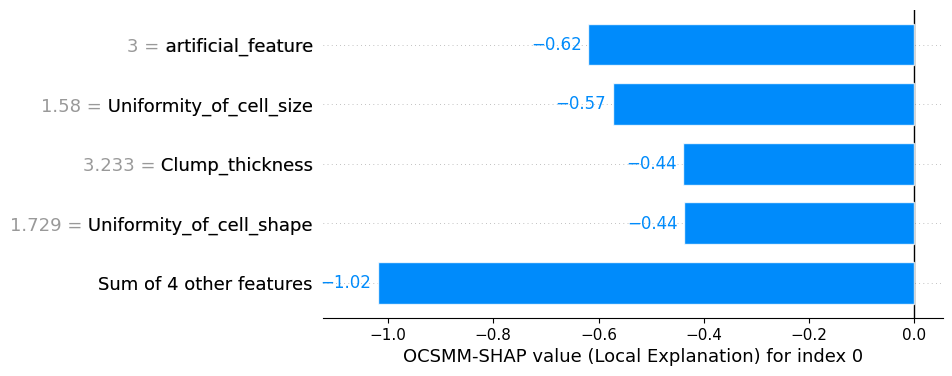

In [49]:
from src.utils.visualisation.deterministic_values import local_bar_plot_ocsmm, global_bar_plot_ocsmm
local_bar_plot_ocsmm(shapley_values.numpy(), 0, feature_names=feature_names, datasets=datasets)

The artificial_feature has the highest shapley value for the altered group as expected

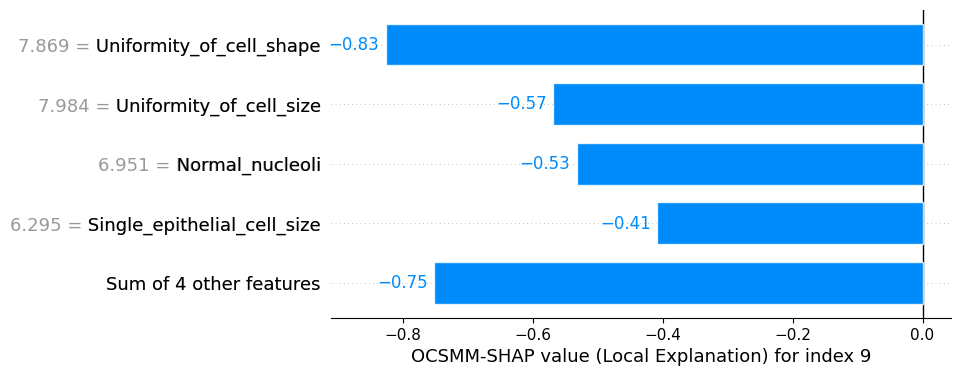

In [50]:
local_bar_plot_ocsmm(shapley_values.numpy(), 9, feature_names=feature_names, datasets=datasets)

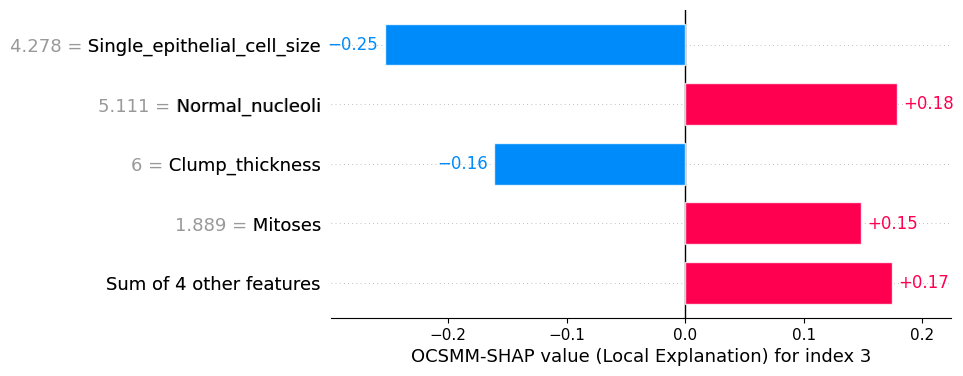

In [51]:
local_bar_plot_ocsmm(shapley_values.numpy(), 3, feature_names=feature_names, datasets=datasets)

/tmp/ipykernel_3407115/3176113499.py:2: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  mean_abs_shap_values = np.abs(shapley_values).mean(axis=0)


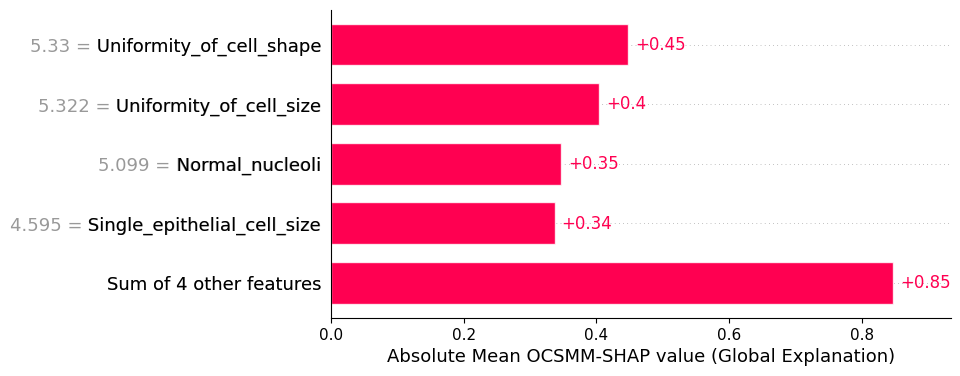

In [52]:
# global importance measure
mean_abs_shap_values = np.abs(shapley_values).mean(axis=0)  

# Call bar_plot for global explanation
global_bar_plot_ocsmm(mean_abs_shap_values.numpy(), feature_names=feature_names, datasets=datasets)

100%|██████████| 256/256 [00:00<00:00, 2093.21it/s]


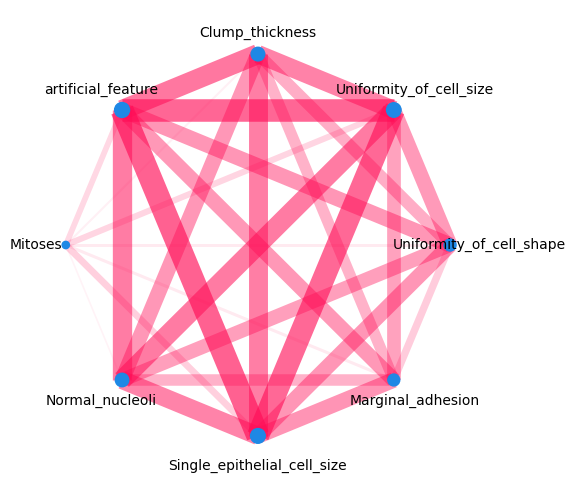

In [54]:
from src.explanation_algorithms.OCSMMSHAPIQ_Approx import OCSMMSHAPIQ, display_network_plot
shapiq = OCSMMSHAPIQ(n=len(feature_names), max_order=2, random_state=2)
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[0],
    X=datasets,  
    model=classifier,
    regularization=1e-6,
    budget=2**len(feature_names))
display_network_plot(interactions_per_group, feature_names=feature_names)

100%|██████████| 256/256 [00:00<00:00, 2472.74it/s]


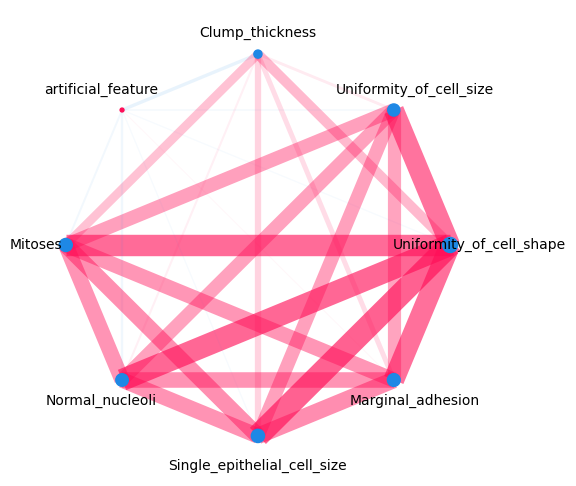

In [56]:
shapiq = OCSMMSHAPIQ(n=len(feature_names), max_order=2, random_state=2)
interactions_per_group = shapiq.explain_single_group(
    group_data=datasets[9],
    X=datasets,  
    model=classifier,
    regularization=1e-6,
    budget=2**len(feature_names))
display_network_plot(interactions_per_group, feature_names=feature_names)